# 01 · EDA com inferência estatística

**Pergunta do notebook:** o que, nos dados, está associado à inadimplência, e com que força?

Aqui eu olho os dados antes de modelar, mas com prova estatística: cada análise termina em **Hipótese → Evidência → Decisão**.

**Regras deste notebook**
- Uso **só o treino** (24.000 clientes). O holdout fica lacrado até a Etapa 13.
- Com 24 mil clientes, quase qualquer diferença sai "estatisticamente significativa". Por isso todo teste vem com um **tamanho de efeito**, que diz se a diferença é grande o bastante para importar.

**Critérios fixados antes de ver os dados**

| Item | Critério |
|---|---|
| Significância | 5%, depois da correção de Holm para múltiplos testes |
| Tamanho de efeito (Cohen) | < 0,10 desprezível · 0,10 pequeno · 0,30 médio · 0,50 grande |
| Variável **relevante** | significativa **e** efeito ≥ pequeno |
| `n_status_bill_mismatch` | vira candidata a feature só se tiver efeito ≥ pequeno |
| Sexo, idade, estado civil | a EDA só descreve; usar ou não no modelo é decidido na modelagem, com checagem de equidade |

Termos novos estão no [Glossário](../docs/GLOSSARIO.md).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats as sps

from credit_risk import config
from credit_risk.split import load_train
from credit_risk.stats import (
    bootstrap_ci,
    chi2_cramers_v,
    mann_whitney_rank_biserial,
    rate_by_group,
    results_table,
)
from credit_risk.viz import CONTEXT, HIGHLIGHT, INK_2, plot_rate_by_group, save, set_style

set_style()
pd.set_option("display.precision", 4)

df = load_train()
y = df[config.TARGET]
LABELS = config.CATEGORY_LABELS
tests = []  # todos os testes entram aqui e são corrigidos juntos por Holm no fim
df.shape

(24000, 28)

## 1. Quanto é a inadimplência, e por que a acurácia engana

**Hipótese:** a taxa de default é próxima de 22%, como diz a documentação.

O número de uma amostra tem margem de erro. Para medir essa margem, uso o **bootstrap**: sorteio 10 mil "amostras parecidas" (com reposição) a partir dos dados e calculo a taxa em cada uma. Os 95% do meio formam o **intervalo de confiança (IC)**.

In [2]:
rate, ci_low, ci_high = bootstrap_ci(y)
print(f"Taxa de default no treino: {rate:.2%}  (IC 95%: {ci_low:.2%} a {ci_high:.2%})")
print(f"Acurácia de um modelo que diz 'ninguém dá default': {1 - rate:.2%}")

Taxa de default no treino: 22.12%  (IC 95%: 21.60% a 22.66%)
Acurácia de um modelo que diz 'ninguém dá default': 77.88%


**Evidência:** a taxa é **22,12%**, com IC 95% de **21,60% a 22,66%**. Um "modelo" que simplesmente diz "ninguém vai dar default" acerta **77,88%** dos casos sem saber nada, e não ajuda em nenhuma decisão.

**Decisão:** acurácia **não** será métrica de escolha. Uso ROC AUC, PR AUC, KS, Brier e, na decisão, o **resultado em dinheiro** (Etapa 9 em diante).

## 2. Perfil do cliente: sexo, escolaridade e estado civil

**Hipótese:** o perfil demográfico tem alguma relação com o default, mas fraca perto do histórico de pagamento.

Para variáveis categóricas uso o **teste qui-quadrado** (verifica se a taxa muda entre categorias) e o **V de Cramér** (mede a força: 0 = nenhuma relação, 1 = a categoria determina o default).

,variable,test,statistic,p_value,effect_name,effect,n
0,sex,qui-quadrado,46.1735,0.0000,Cramér V,0.0439,24000
1,education,qui-quadrado,125.1813,0.0000,Cramér V,0.0722,24000
2,marriage,qui-quadrado,19.5430,0.0001,Cramér V,0.0285,24000


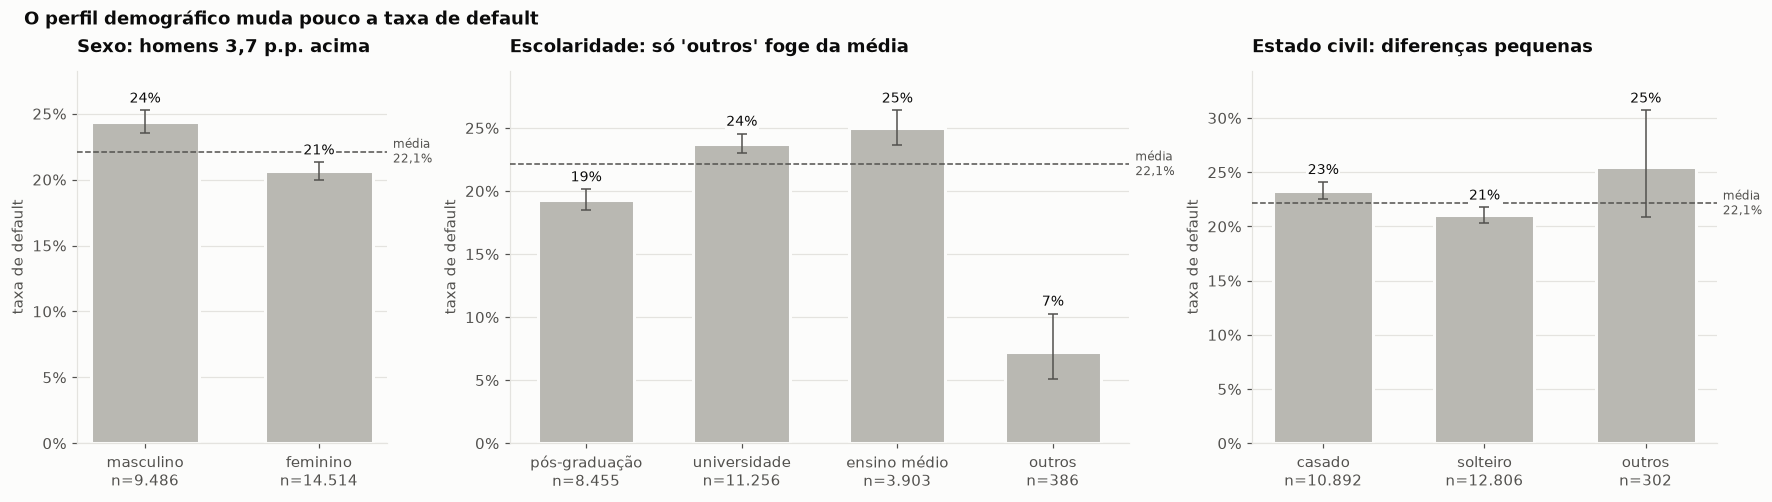

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [2, 4, 3]})
for ax, col in zip(axes, ["sex", "education", "marriage"], strict=True):
    plot_rate_by_group(rate_by_group(df, col), col, col, rate, labels=LABELS[col], ax=ax)
    tests.append(chi2_cramers_v(df[col], y))
axes[0].set_title("Sexo: homens 3,7 p.p. acima")
axes[1].set_title("Escolaridade: só 'outros' foge da média")
axes[2].set_title("Estado civil: diferenças pequenas")
fig.suptitle(
    "O perfil demográfico muda pouco a taxa de default",
    x=0.01,
    ha="left",
    fontweight="bold",
    y=1.05,
)
save(fig, "eda_01_perfil")
pd.DataFrame([t.__dict__ for t in tests]).round(4)

**Evidência:** todas as diferenças são estatisticamente significativas, mas os efeitos são **desprezíveis** (V entre 0,03 e 0,07). A categoria "outros" de escolaridade tem taxa bem menor (7%), mas é um grupo de só 386 clientes.

### Significância ≠ relevância

Os homens têm 24,4% de default contra 20,7% das mulheres. O p-valor é minúsculo, mas o efeito é desprezível. A explicação é o **tamanho da amostra**: com 24 mil pessoas, até uma diferença pequena vira "certeza estatística". Veja o que acontece com **as mesmas taxas** em amostras menores:

In [4]:
table = pd.crosstab(df["sex"], y)
rows = []
for n in [500, 2_000, 5_000, len(df)]:
    scaled = (table / table.to_numpy().sum() * n).round()
    p = sps.chi2_contingency(scaled, correction=False)[1]
    rows.append({"clientes": n, "p_valor": p, "significativo a 5%": p < 0.05})
pd.DataFrame(rows)

,clientes,p_valor,significativo a 5%
0,500,3.1234e-01,False
1,2000,4.8926e-02,True
2,5000,1.8446e-03,True
3,24000,1.0823e-11,True


A diferença entre as taxas é **a mesma** em todas as linhas; só o tamanho da amostra muda. Com 500 clientes ela não é significativa, e com 24 mil é "altamente significativa". O p-valor responde *"existe diferença?"*, não *"a diferença importa?"*. Quem responde a segunda pergunta é o tamanho de efeito.

**Decisão:** sexo, escolaridade e estado civil **não são relevantes** pelo critério. Ficam disponíveis para o modelo testar (a escolaridade "outros" pode ajudar em um modelo de árvore), mas não guiam a política. O uso de sexo e estado civil será decidido com a checagem de equidade.

## 3. Idade e limite de crédito

**Hipótese:** clientes com limite maior dão menos default (o banco já deu mais crédito a quem considerou melhor pagador). A idade tem efeito pequeno.

Para variáveis numéricas uso o **teste de Mann-Whitney**, que compara as duas distribuições sem supor que elas tenham forma de sino. O efeito é a **correlação rank-biserial** (r): sorteando um inadimplente e um adimplente, a chance de o inadimplente ter o valor maior é `(r + 1) / 2`.

,variable,test,statistic,p_value,effect_name,effect,n
0,limit_bal,Mann-Whitney,3.7367e+07,0.000,rank-biserial,-0.2469,24000
1,age,Mann-Whitney,4.9846e+07,0.605,rank-biserial,0.0046,24000
2,age_band,qui-quadrado,9.6477e+01,0.000,Cramér V,0.0634,24000


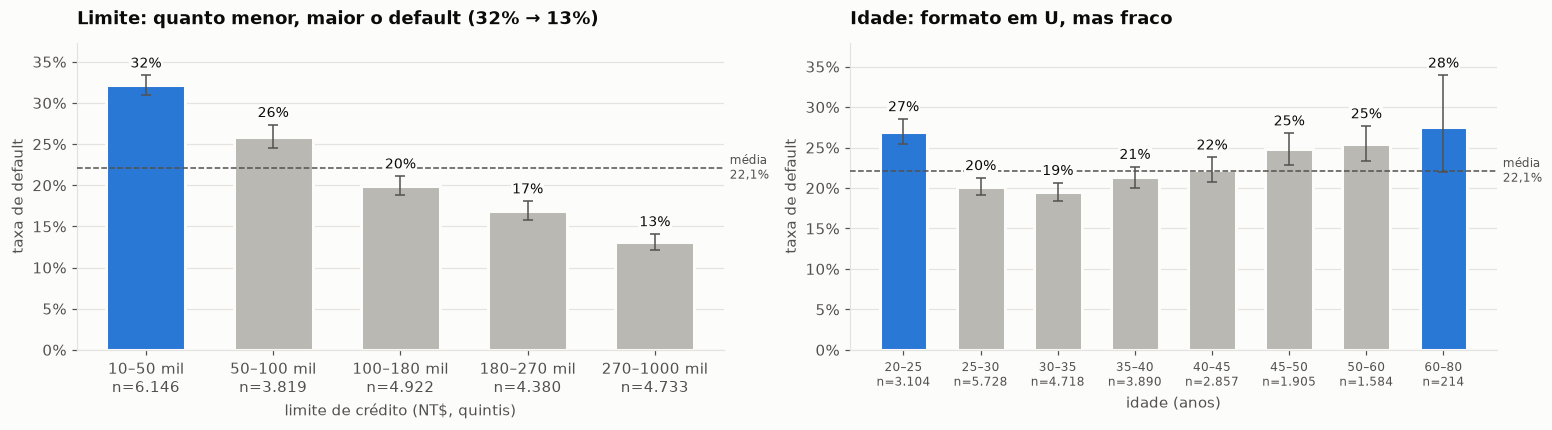

In [5]:
df["limit_band"] = pd.qcut(df["limit_bal"], 5)
df["age_band"] = pd.cut(df["age"], [20, 25, 30, 35, 40, 45, 50, 60, 80])
limit_rates = rate_by_group(df, "limit_band")
age_rates = rate_by_group(df, "age_band")


def band_label(iv, scale=1, suffix=""):
    return f"{iv.left / scale:.0f}–{iv.right / scale:.0f}{suffix}"


fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
plot_rate_by_group(
    limit_rates,
    "limit_band",
    "Limite: quanto menor, maior o default (32% → 13%)",
    rate,
    highlight=[limit_rates["limit_band"].iloc[0]],
    labels={iv: band_label(iv, 1000, " mil") for iv in limit_rates["limit_band"]},
    xlabel="limite de crédito (NT$, quintis)",
    ax=axes[0],
)
plot_rate_by_group(
    age_rates,
    "age_band",
    "Idade: formato em U, mas fraco",
    rate,
    highlight=[age_rates["age_band"].iloc[0], age_rates["age_band"].iloc[-1]],
    labels={iv: band_label(iv) for iv in age_rates["age_band"]},
    xlabel="idade (anos)",
    ax=axes[1],
)
save(fig, "eda_02_limite_idade")

for col in ["limit_bal", "age"]:
    tests.append(mann_whitney_rank_biserial(df[col], y))
tests.append(chi2_cramers_v(df["age_band"].astype(str).rename("age_band"), y))
pd.DataFrame([t.__dict__ for t in tests[-3:]]).round(4)

**Evidência:**
- **Limite:** a taxa cai de forma contínua, de **32%** no quinto de menor limite para **13%** no de maior. Rank-biserial = **-0,25** (efeito pequeno): sorteando um inadimplente e um adimplente, o inadimplente tem limite menor em cerca de 62% das vezes.
- **Idade:** o Mann-Whitney dá efeito **zero** (r = 0,005), mas o gráfico mostra um **U**: 27% entre 21 e 25 anos, 19% entre 30 e 35, e 28% acima de 60. O Mann-Whitney só detecta "um grupo tende a ter valores maiores"; numa relação em U, as duas pontas se cancelam. Testando as faixas de idade com qui-quadrado, o V é **0,063**: o U é real, mas ainda **desprezível**.

**Lição de método:** um teste "sem efeito" não prova que não há relação; ele só prova que não há a relação **que aquele teste procura**. Por isso olho sempre o gráfico junto com o número.

**Decisão:** o limite é **relevante** e entra no modelo (e na feature de utilização do limite, Etapa 7). A idade **não é relevante** pelo critério. Se entrar no modelo, modelos de árvore conseguem capturar o U sozinhos; a regressão logística precisaria de faixas.

## 4. Histórico de pagamento: o sinal mais forte

**Hipótese:** o atraso recente é o melhor indicador de default, e meses mais antigos dizem menos.

Lembrando a escala do `pay_status`: -2 e -1 = pagou, 0 = pagou o mínimo (rotativo), 1 a 8 = meses de atraso.

,pay_status_1,n,defaults,taxa,ic_inf,ic_sup
0,-2,2198,279,0.127,0.114,0.142
1,-1,4527,753,0.166,0.156,0.177
2,0,11781,1508,0.128,0.122,0.134
3,1,3000,1031,0.344,0.327,0.361
4,2,2138,1483,0.694,0.674,0.713
5,3,245,188,0.767,0.711,0.816
6,4,58,38,0.655,0.527,0.764
7,5,18,8,0.444,0.246,0.663
8,6,10,6,0.600,0.313,0.832
9,7,9,7,0.778,0.453,0.937


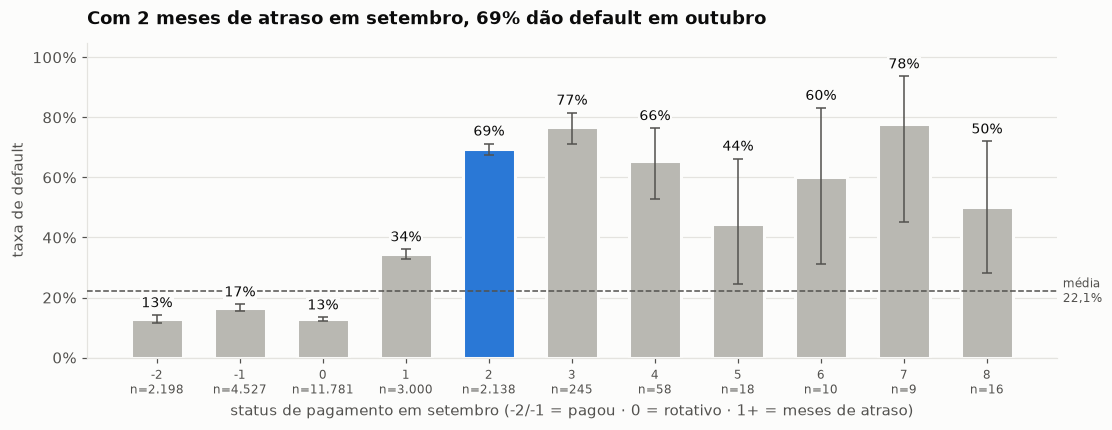

In [6]:
status_rates = rate_by_group(df, "pay_status_1")
fig, ax = plt.subplots(figsize=(10, 3.8))
plot_rate_by_group(
    status_rates,
    "pay_status_1",
    "Com 2 meses de atraso em setembro, 69% dão default em outubro",
    rate,
    highlight=[2],
    xlabel=(
        "status de pagamento em setembro (-2/-1 = pagou · 0 = rotativo · 1+ = meses de atraso)"
    ),
    ax=ax,
)
save(fig, "eda_03_status_setembro")
status_rates.round(3)

**Evidência:** a taxa salta de **13%** (status 0) para **34%** com 1 mês de atraso e **69%** com 2 meses. Acima de 3 meses os grupos são minúsculos (9 a 58 clientes), e os intervalos ficam muito largos.

**Cuidado com o teste:** o qui-quadrado só é confiável quando cada célula da tabela **espera** pelo menos 5 casos. Com status 5 a 8 isso não acontece. Antes de testar, agrupo os status raros e confiro:

In [7]:
def min_expected(x: pd.Series) -> float:
    return sps.chi2_contingency(pd.crosstab(x, y), correction=False)[3].min()


def group_status(s: pd.Series) -> pd.Series:
    # junta atrasos >= 3 em "3+"; junta 1 com 2 só se o status 1 for raro demais
    groups = s.map(lambda v: str(v) if v <= 2 else "3+").rename(s.name)
    if min_expected(groups) < 5:
        groups = groups.replace({"1": "1–2", "2": "1–2"})
    return groups


rows = []
for col in config.PAY_STATUS:
    grouped = group_status(df[col])
    res = chi2_cramers_v(grouped, y)
    tests.append(res)
    rows.append(
        {
            "mês": col,
            "clientes com status 1": int((df[col] == 1).sum()),
            "grupos": " ".join(
                sorted(grouped.unique(), key=lambda g: float(g.split("–")[0].rstrip("+")))
            ),
            "esperado mín. (bruto)": min_expected(df[col]),
            "esperado mín. (agrupado)": min_expected(grouped),
            "Cramér V": res.effect,
        }
    )
recency = pd.DataFrame(rows)
assert (recency["esperado mín. (agrupado)"] >= 5).all()
recency.round(3)

,mês,clientes com status 1,grupos,esperado mín. (bruto),esperado mín. (agrupado),Cramér V
0,pay_status_1,3000,-2 -1 0 1 2 3+,1.991,78.750,0.424
1,pay_status_2,25,-2 -1 0 1 2 3+,0.221,5.530,0.341
2,pay_status_3,3,-2 -1 0 1–2 3+,0.442,68.353,0.297
3,pay_status_4,2,-2 -1 0 1–2 3+,0.221,59.284,0.279
4,pay_status_5,0,-2 -1 0 2 3+,0.221,57.957,0.267
5,pay_status_6,0,-2 -1 0 2 3+,0.221,53.975,0.250


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/eda_04_recencia.png')

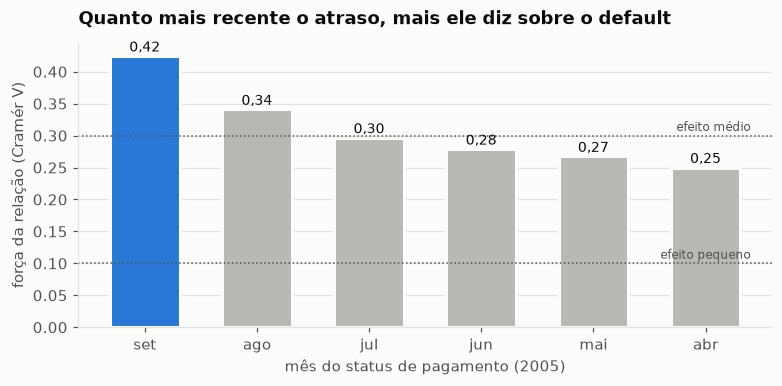

In [8]:
months = ["set", "ago", "jul", "jun", "mai", "abr"]
fig, ax = plt.subplots(figsize=(7, 3.4))
colors = [HIGHLIGHT] + [CONTEXT] * 5
ax.bar(months, recency["Cramér V"], color=colors, width=0.62, edgecolor="#fcfcfb", linewidth=2)
for i, v in enumerate(recency["Cramér V"]):
    ax.annotate(
        f"{v:.2f}".replace(".", ","),
        (i, v),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
for name, thr in config.EFFECT_THRESHOLDS.items():
    if thr < 0.5:
        ax.axhline(thr, color=INK_2, linestyle=":", linewidth=1)
        ax.annotate(
            f"efeito {name}",
            (5.4, thr),
            xytext=(0, 3),
            textcoords="offset points",
            ha="right",
            fontsize=8,
            color=INK_2,
        )
ax.set_ylabel("força da relação (Cramér V)")
ax.set_xlabel("mês do status de pagamento (2005)")
ax.set_title("Quanto mais recente o atraso, mais ele diz sobre o default")
save(fig, "eda_04_recencia")

**Evidência:** o status 1 quase não aparece de agosto para trás (uma peculiaridade conhecida desta base), por isso nesses meses ele precisa ser juntado ao 2. Depois do agrupamento, todas as células esperam ≥ 5 casos (o teste fica válido). O status de **setembro** tem V = **0,42 (efeito médio)**, o maior de toda a base, e a força **cai mês a mês** até **0,25** em abril.

**Decisão:**
- O histórico de pagamento é o **sinal principal**, e o mês mais recente vale mais.
- Para a Etapa 7: criar features de **atraso máximo**, **número de meses em atraso** e **atraso recente vs. antigo** (tendência), em vez de tratar os 6 meses como iguais.
- Na regressão logística, `pay_status` não deve entrar como número contínuo (de -2 para -1 não é "1 mês a mais de atraso"); as faixas ou flags de atraso são mais honestas.

## 5. Valores da fatura e dos pagamentos

**Hipótese:** quem paga menos tem mais risco; o valor da fatura sozinho diz pouco (uma fatura alta pode ser de um cliente rico e bom pagador).

,variable,effect,p_value
0,bill_amt_1,-0.0323,0.0003
1,bill_amt_2,-0.0195,0.0299
2,bill_amt_3,-0.0163,0.0690
3,bill_amt_4,-0.0120,0.1811
4,bill_amt_5,-0.0085,0.3421
5,bill_amt_6,0.0042,0.6419
6,pay_amt_1,-0.2252,0.0000
7,pay_amt_2,-0.2095,0.0000
8,pay_amt_3,-0.1962,0.0000
9,pay_amt_4,-0.1721,0.0000


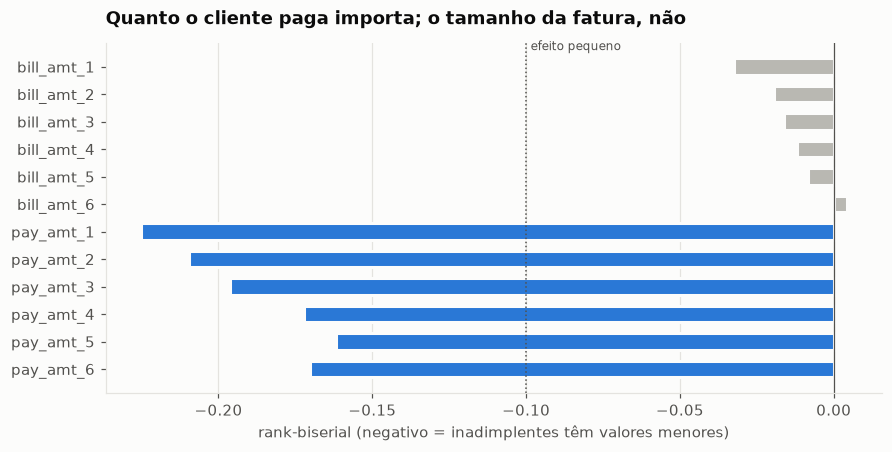

In [9]:
amount_tests = [mann_whitney_rank_biserial(df[c], y) for c in config.BILL_AMT + config.PAY_AMT]
tests.extend(amount_tests)
amounts = pd.DataFrame([t.__dict__ for t in amount_tests])[["variable", "effect", "p_value"]]

fig, ax = plt.subplots(figsize=(8, 4))
colors = [HIGHLIGHT if v.startswith("pay_amt") else CONTEXT for v in amounts["variable"]]
ax.barh(
    amounts["variable"],
    amounts["effect"],
    color=colors,
    height=0.6,
    edgecolor="#fcfcfb",
    linewidth=2,
)
ax.axvline(-0.10, color=INK_2, linestyle=":", linewidth=1)
ax.annotate(
    "efeito pequeno",
    (-0.10, -0.6),
    xytext=(3, 0),
    textcoords="offset points",
    fontsize=8,
    color=INK_2,
)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.invert_yaxis()
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("rank-biserial (negativo = inadimplentes têm valores menores)")
ax.set_title("Quanto o cliente paga importa; o tamanho da fatura, não")
save(fig, "eda_05_valores")
amounts.round(4)

**Evidência:**
- **Pagamentos (`pay_amt`)**: os inadimplentes pagam menos em todos os meses, com efeito **pequeno** (r de -0,16 a -0,23), mais forte no mês mais recente.
- **Faturas (`bill_amt`)**: efeito **desprezível** em todos os meses (|r| ≤ 0,032), e vários nem são significativos após Holm.

**Decisão:** o valor absoluto da fatura não ajuda, mas ele pode ganhar sentido **em relação a algo**. Na Etapa 7: **utilização do limite** (fatura ÷ limite) e **taxa de pagamento** (pagamento ÷ fatura do mês anterior). Hipótese a testar: uma fatura de NT$ 50 mil é pouco para um limite de 500 mil e muito para um de 50 mil.

## 6. Qualidade dos dados: o que significa o status -2?

Na Etapa 4 encontrei **15% dos clientes com meses "contraditórios"**: status -2 ("sem consumo", pela interpretação usual) com fatura positiva, ou status de atraso com fatura zero. Agora investigo de onde isso vem.

**Hipótese:** a interpretação usual de -2 está errada, e as "contradições" são um artefato dela.

In [10]:
prev_bill = df["bill_amt_2"].where(df["bill_amt_2"] > 0)
behaviour = (
    df.assign(pagou_da_fatura_anterior=df["pay_amt_1"] / prev_bill)
    .groupby("pay_status_1")
    .agg(
        clientes=("id", "size"),
        fatura_set_mediana=("bill_amt_1", "median"),
        pagou_da_fatura_anterior=("pagou_da_fatura_anterior", "median"),
    )
    .loc[[-2, -1, 0]]
)
behaviour

,clientes,fatura_set_mediana,pagou_da_fatura_anterior
pay_status_1,,,
-2,2198,1246.0,1.0000
-1,4527,2667.0,1.0000
0,11781,49624.0,0.0571


,variable,test,statistic,p_value,effect_name,effect,n
0,n_status_bill_mismatch,Mann-Whitney,4.7795e+07,0.0,rank-biserial,-0.0367,24000
1,n_status_bill_mismatch (faixas),qui-quadrado,1.7829e+02,0.0,Cramér V,0.0862,24000


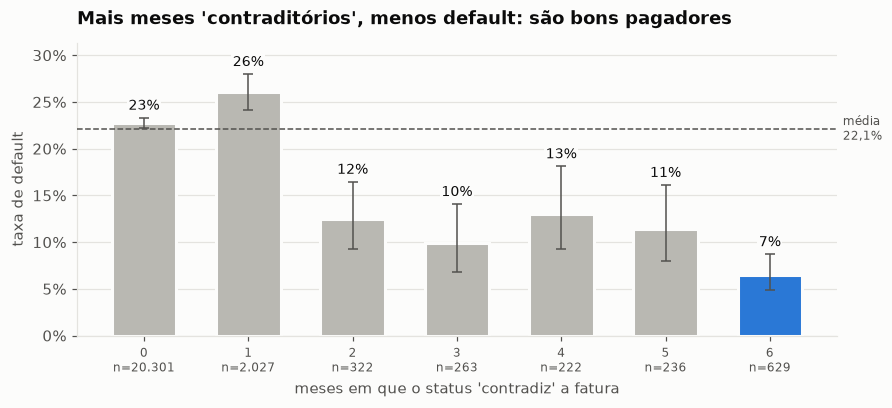

In [11]:
mismatch_rates = rate_by_group(df, "n_status_bill_mismatch")
tests.append(mann_whitney_rank_biserial(df["n_status_bill_mismatch"], y))
tests.append(
    chi2_cramers_v(df["n_status_bill_mismatch"].rename("n_status_bill_mismatch (faixas)"), y)
)
fig, ax = plt.subplots(figsize=(8, 3.6))
plot_rate_by_group(
    mismatch_rates,
    "n_status_bill_mismatch",
    "Mais meses 'contraditórios', menos default: são bons pagadores",
    rate,
    highlight=[6],
    xlabel="meses em que o status 'contradiz' a fatura",
    ax=ax,
)
save(fig, "eda_06_status_menos2")
pd.DataFrame([t.__dict__ for t in tests[-2:]]).round(4)

**Evidência:**
- Quem tem status **-2** em setembro tem **fatura positiva** (mediana de NT$ 1.246) e **pagou 100%** da fatura anterior (mediana). O mesmo vale para o -1. Já o status **0** paga só **cerca de 6%** da fatura, o que confirma a leitura "pagou o mínimo / rotativo".
- Os clientes com **6 meses "contraditórios"** são quase todos status -2 o tempo todo, e têm a **menor** taxa de default (6,5%).

**Conclusão:** -2 **não** significa "sem consumo". O comportamento é de quem **quita a fatura inteira**, com saldo baixo. As "contradições" da Etapa 4 vêm, em sua maioria, da interpretação errada, e não de erro nos dados.

**Decisão (pelo critério fixado):** `n_status_bill_mismatch` tem efeito **desprezível** nos dois testes (r = -0,04; V = 0,09). **Não vira feature.** O data card é atualizado com a nova interpretação de -2. Nas features da Etapa 7, -2 e -1 são tratados como "pagou em dia".

## 7. Quadro geral, com correção para múltiplos testes

Fiz muitos testes neste notebook. A 5% de significância, **1 em cada 20 testes** pode dar "positivo" só por acaso. A **correção de Holm** deixa cada teste mais exigente para compensar: o menor p-valor é multiplicado pelo número de testes, o segundo menor pelo número menos 1, e assim por diante.

In [12]:
for col in ["education_undocumented", "marriage_undocumented"]:
    tests.append(chi2_cramers_v(df[col], y))

summary = results_table(tests)
summary.to_csv(config.REPORTS_DIR / "eda_tests.csv", index=False)
cols = ["variable", "test", "effect_name", "effect", "p_holm", "magnitude", "relevante"]
n_relevant = summary["relevante"].sum()
n_noise = (summary["significativo"] & ~summary["relevante"]).sum()
print(
    f"{len(summary)} testes | relevantes: {n_relevant} | significativos mas desprezíveis: {n_noise}"
)
summary[cols].round(4)

28 testes | relevantes: 13 | significativos mas desprezíveis: 8


,variable,test,effect_name,effect,p_holm,magnitude,relevante
0,pay_status_1,qui-quadrado,Cramér V,0.4245,0.0000,médio,True
1,pay_status_2,qui-quadrado,Cramér V,0.3408,0.0000,médio,True
2,pay_status_3,qui-quadrado,Cramér V,0.2965,0.0000,pequeno,True
3,pay_status_4,qui-quadrado,Cramér V,0.2787,0.0000,pequeno,True
4,pay_status_5,qui-quadrado,Cramér V,0.2673,0.0000,pequeno,True
5,pay_status_6,qui-quadrado,Cramér V,0.2500,0.0000,pequeno,True
6,limit_bal,Mann-Whitney,rank-biserial,-0.2469,0.0000,pequeno,True
7,pay_amt_1,Mann-Whitney,rank-biserial,-0.2252,0.0000,pequeno,True
8,pay_amt_2,Mann-Whitney,rank-biserial,-0.2095,0.0000,pequeno,True
9,pay_amt_3,Mann-Whitney,rank-biserial,-0.1962,0.0000,pequeno,True


PosixPath('/home/renan/projetos/credit-risk-semantix/reports/figures/eda_07_resumo_efeitos.png')

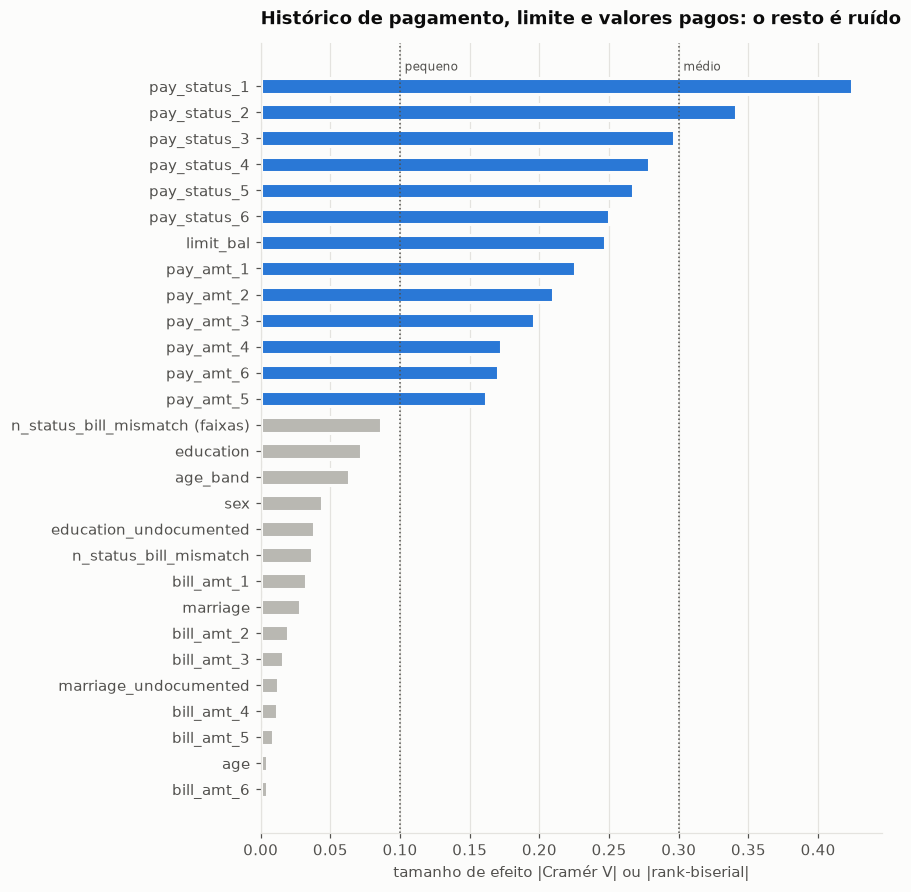

In [13]:
plot_df = summary.assign(abs_effect=summary["effect"].abs()).sort_values("abs_effect")
fig, ax = plt.subplots(figsize=(8, 8))
colors = [HIGHLIGHT if r else CONTEXT for r in plot_df["relevante"]]
ax.barh(
    plot_df["variable"],
    plot_df["abs_effect"],
    color=colors,
    height=0.6,
    edgecolor="#fcfcfb",
    linewidth=2,
)
for name, thr in config.EFFECT_THRESHOLDS.items():
    if thr < 0.5:
        ax.axvline(thr, color=INK_2, linestyle=":", linewidth=1)
        ax.annotate(
            name,
            (thr, len(plot_df) - 0.4),
            xytext=(3, 0),
            textcoords="offset points",
            fontsize=8,
            color=INK_2,
        )
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("tamanho de efeito |Cramér V| ou |rank-biserial|")
ax.set_title("Histórico de pagamento, limite e valores pagos: o resto é ruído")
save(fig, "eda_07_resumo_efeitos")

## 8. Conclusões da EDA

| # | Achado | Decisão para as próximas etapas |
|---|---|---|
| 1 | Default de **22,12%** (IC 95%: 21,60%–22,66%); a acurácia de "ninguém dá default" é **77,88%** | acurácia não é métrica de escolha |
| 2 | **Status de pagamento** é o sinal mais forte (V = 0,42 em setembro) e enfraquece com o tempo (0,25 em abril) | features de atraso máximo, meses em atraso e tendência (Etapa 7) |
| 3 | **Limite** de crédito: 32% de default no quinto menor e 13% no maior (r = -0,25) | entra no modelo e na utilização do limite |
| 4 | **Pagamentos** importam (r até -0,23); **faturas** sozinhas não (\|r\| ≤ 0,032) | razões pagamento ÷ fatura e fatura ÷ limite (Etapa 7) |
| 5 | Sexo, escolaridade, estado civil e idade: significativos, mas **desprezíveis** | não guiam a política; uso no modelo decidido com checagem de equidade |
| 6 | Status **-2 = quitou a fatura**, não "sem consumo"; as "contradições" eram um artefato | `n_status_bill_mismatch` não vira feature; data card corrigido |
| 7 | Com n = 24 mil, **significância ≠ relevância** | todo teste daqui em diante vem com tamanho de efeito |

**Limite desta análise:** tudo aqui é **associação**, não causa. Um limite baixo não *causa* default; o banco deu limite baixo a quem já considerava arriscado. Para prever, isso basta. Para recomendar uma ação ("aumentar o limite reduz o risco"), não.

Resultados completos em `reports/eda_tests.csv`; gráficos em `reports/figures/eda_*.png`.